# Parallelism
Given a dataframe with one row per mutation, each labeled as "branch1", "branch2" or "other", compute the similarity between the two branches: the cosine similarity between the number of mutations in each functional unit (gene or COG pathway).
This is compared with a null distribution where the branch labels are randomly shuffled between all the mutations (including "other"), preserving the mutation count per branch.

Each mutation can affect several units (genes in the downstream operon for intergenic mutations, several COG pathways for some genes). The labels are shuffled per mutation, so that a mutation always carries all its units into the same branch.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = Path('../../../datasets/genomics')
RESULTS = DATA / '08_convergence/results/cosine_similarities'


def cosine_similarity(counts1, counts2) -> float:
    norm = np.linalg.norm(counts1) * np.linalg.norm(counts2)
    return np.dot(counts1, counts2) / norm if norm > 0 else np.nan


def mutation_to_groups(mutations, context_to_group):
    '''One row per (mutation, group) pair. Returns the mutation index and group code of each pair, and the number of groups.'''
    pairs = (mutations[['context']]
             .reset_index(drop=True)
             .rename_axis('mutation')
             .reset_index()
             .merge(context_to_group, on='context', how='left')
             .dropna(subset=['group']))
    group_codes = pd.Categorical(pairs['group']).codes
    return pairs['mutation'].values, group_codes, group_codes.max() + 1


def branch_similarity(branches, mutation_idx, group_codes, n_groups, population1='branch1', population2='branch2'):
    '''Similarity between the group counts of two branches. branches: one label per mutation.'''
    pair_branches = branches[mutation_idx]
    counts1 = np.bincount(group_codes[pair_branches == population1], minlength=n_groups)
    counts2 = np.bincount(group_codes[pair_branches == population2], minlength=n_groups)
    return cosine_similarity(counts1, counts2)


def pairwise_comparison(mutations, context_to_group, population1, population2):
    '''Calculate observed similarity between two populations'''
    mutation_idx, group_codes, n_groups = mutation_to_groups(mutations, context_to_group)
    return branch_similarity(mutations['branch'].values, mutation_idx, group_codes, n_groups, population1, population2)


def run_permutation_test(mutations, context_to_group, n_permutations=10000, random_seed=None):
    '''Compare the observed similarity between branch1 and branch2 to a null distribution where branch labels are shuffled between mutations.'''
    rng = np.random.default_rng(random_seed)
    mutation_idx, group_codes, n_groups = mutation_to_groups(mutations, context_to_group)
    branches = mutations['branch'].values

    observed = branch_similarity(branches, mutation_idx, group_codes, n_groups)
    null = np.array([
        branch_similarity(rng.permutation(branches), mutation_idx, group_codes, n_groups)
        for _ in range(n_permutations)
    ])

    # Permutation p-values, counting the observed configuration as one of the permutations
    p_more = (1 + np.sum(null >= observed)) / (1 + n_permutations) # more similar than chance
    p_less = (1 + np.sum(null <= observed)) / (1 + n_permutations) # less similar than chance
    p_two_sided = min(1, 2 * min(p_more, p_less))

    print(f'Observed similarity: {observed:.4f} (null mean {null.mean():.4f})')
    print(f'p (more similar) = {p_more:.4f}, p (less similar) = {p_less:.4f}, two-sided p = {p_two_sided:.4f}')
    return {'observed': observed, 'p_value': p_two_sided, 'p_more_similar': p_more, 'p_less_similar': p_less,
            'null_distribution': null.tolist()}


def plot_results(results, bins=50):
    '''Plot the null distribution and observed value.'''
    fig, ax = plt.subplots(figsize=(5, 2))
    ax.hist(results['null_distribution'], bins=bins, color='lightgrey', edgecolor='grey', density=True)
    ax.axvline(results['observed'], color='black')
    ax.set_xlabel('Similarity')
    ax.set_ylabel('Density')
    ax.set_title(f"two-sided p = {results['p_value']:.4f}")
    plt.show()


def write_json(name, results):
    with open(RESULTS / f'{name}.json', 'w') as f:
        json.dump(results, f)

# Load data

In [2]:
# Main experiment
v = pd.read_csv(DATA / '04_gene_attribution/results/v.tsv', sep = '\t')

# Replays
v_replays = pd.read_csv(DATA / '04_gene_attribution/results/v_replays.tsv', sep = '\t')

v_all = pd.read_csv(DATA / '04_gene_attribution/results/v_all.tsv', sep = '\t')
# Exclude variants present from the beginning
initial_variants = np.unique(v_all[(v_all['origin'] == 'I')]['vid'])
# For the A replays, exclude variants already detected in A before the take-over
variants_from_A = (v[(v['pop'] == 'A') & (v['gen'] <= 12)])['vid']
v_replays = v_replays[
    (~v_replays.vid.isin(initial_variants)) &
    (~v_replays['vid'].isin(variants_from_A))
]

v_union = pd.concat([v, v_replays])

In [3]:
# Nearly-fixed variants, excluding changes in long repeats and synonymous mutations
v_filt = v_union[
    (v_union.rep_len < 5) &
    (v_union.max_f > 0.9) &
    (v_union.cat != 'synonymous')
].reset_index(drop=True)

# Map contexts to genes and COG pathways

In [4]:
# Gene level: intergenic contexts affect all the genes of the downstream transcription units
context_to_gene_raw = pd.read_csv(DATA / '05_genome_mapping/results/context_to_affected.tsv', sep = '\t')
context_to_gene_raw['group'] = context_to_gene_raw.affected.str.split(',')
context_to_gene = context_to_gene_raw.explode('group').reset_index(drop=True)[['context', 'group']]

# Pathway level: genes without COG annotation are left out; genes in several pathways count in each of them
gene_to_COG = pd.read_csv(DATA / 'external_datasets/COG/gene_name_to_COG_info.tsv', sep = '\t')
context_to_COG = context_to_gene.rename(columns = {'group': 'gene_name'}).merge(gene_to_COG, how = 'left')[['context', 'letter']]
context_to_COG.columns = ['context', 'group']

levels = {'gene': context_to_gene, 'cog': context_to_COG}

# All pairwise comparisons
Cross-contaminations (in units of 2,500 generations, see `lineages.tsv`):
* 8: F to H
* 12: H to E
* 13: F to G
* 12: A takes over all the reactors; the main experiment restarts from the 12 checkpoint

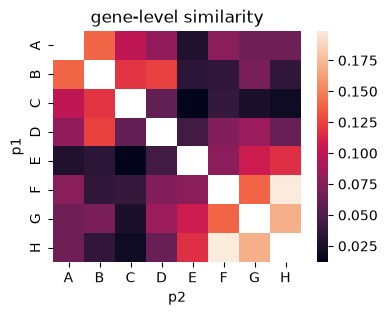

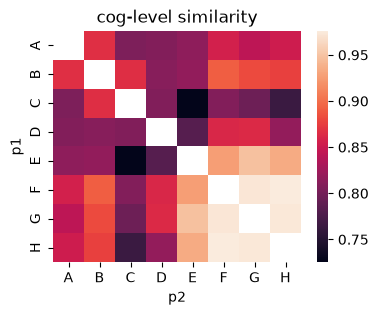

In [5]:
for level, context_to_group in levels.items():
    # After 2h-transfers (all the replays are after that)
    mutations = v_filt[(v_filt.gen > 8) | (v_filt['pop'].str.len() > 1)].reset_index(drop=True)
    mutations['branch'] = mutations['pop']

    pops = np.unique(mutations['pop'])
    sim_df = pd.DataFrame(
        [(p1, p2, pairwise_comparison(mutations, context_to_group, p1, p2)) for p1 in pops for p2 in pops],
        columns = ['p1', 'p2', 'obs_sim']
    )
    sim_df.to_csv(RESULTS / f'sim_df_{level}.tsv', sep = '\t', index = False)

    main = sim_df[
        (sim_df['p1'].str.len() == 1) & (sim_df['p2'].str.len() == 1) &
        (~sim_df['p1'].isin(['X', 'Y', 'Z'])) & (~sim_df['p2'].isin(['X', 'Y', 'Z'])) &
        (sim_df['p1'] != sim_df['p2'])
    ]
    plt.figure(figsize=(4, 3))
    sns.heatmap(main.pivot(index = 'p1', columns = 'p2', values = 'obs_sim'))
    plt.title(f'{level}-level similarity')
    plt.show()

# Branches following each cross-contamination
For each event, the mutations that appeared afterwards in the two branches are compared, with the null distribution drawn from the mutations of all the populations shown in the corresponding tree (N3).


### F_vs_H: {'branch1': ['E', 'H'], 'branch2': ['F', 'G'], 'other': ['A', 'B', 'C', 'D', 'X', 'Y']}
{'branch2': 747, 'branch1': 710, 'other': 184}

F_vs_H, gene level


Observed similarity: 0.2608 (null mean 0.2491)
p (more similar) = 0.2332, p (less similar) = 0.7669, two-sided p = 0.4664


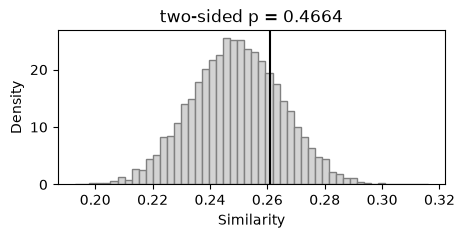


F_vs_H, cog level


Observed similarity: 0.9841 (null mean 0.9833)
p (more similar) = 0.5214, p (less similar) = 0.4787, two-sided p = 0.9573


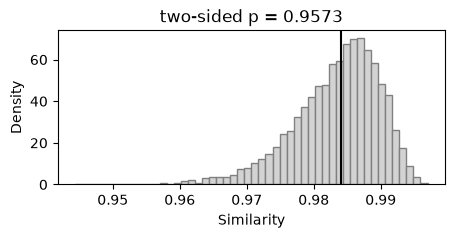


### H_vs_E: {'branch1': ['E'], 'branch2': ['H'], 'other': ['F', 'G']}
{'other': 710, 'branch2': 486, 'branch1': 164}

H_vs_E, gene level


Observed similarity: 0.1100 (null mean 0.1068)
p (more similar) = 0.4228, p (less similar) = 0.5773, two-sided p = 0.8455


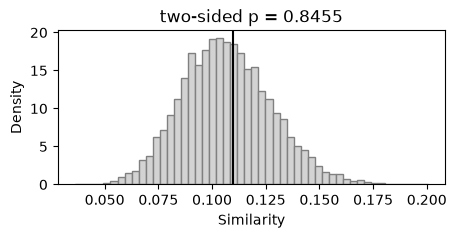


H_vs_E, cog level


Observed similarity: 0.9313 (null mean 0.9544)
p (more similar) = 0.8959, p (less similar) = 0.1042, two-sided p = 0.2084


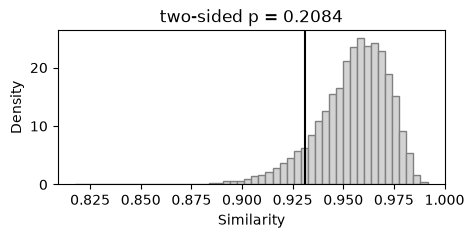


### F_vs_G: {'branch1': ['F'], 'branch2': ['G'], 'other': ['E', 'H']}
{'other': 550, 'branch2': 339, 'branch1': 329}

F_vs_G, gene level


Observed similarity: 0.1173 (null mean 0.1309)
p (more similar) = 0.7360, p (less similar) = 0.2641, two-sided p = 0.5281


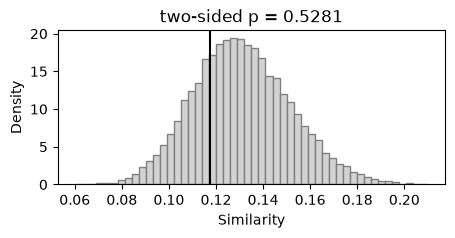


F_vs_G, cog level


Observed similarity: 0.9735 (null mean 0.9665)
p (more similar) = 0.3407, p (less similar) = 0.6594, two-sided p = 0.6813


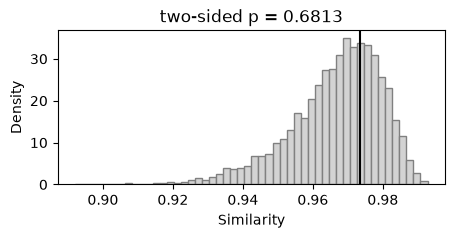


### A_takeover: {'branch1': ['A'], 'branch2': ['AA', 'AB', 'AC', 'AD', 'AE', 'AF', 'AG', 'AH'], 'other': ['B', 'C', 'D']}
{'other': 134, 'branch2': 93, 'branch1': 39}

A_takeover, gene level


Observed similarity: 0.2970 (null mean 0.2006)
p (more similar) = 0.0978, p (less similar) = 0.9024, two-sided p = 0.1956


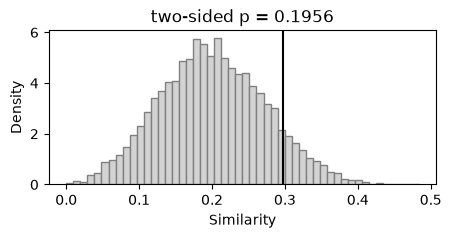


A_takeover, cog level


Observed similarity: 0.8875 (null mean 0.8294)
p (more similar) = 0.1835, p (less similar) = 0.8166, two-sided p = 0.3670


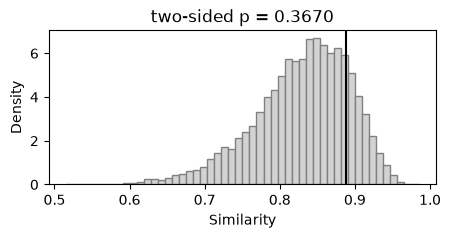

In [6]:
EFGH = ['E', 'F', 'G', 'H']
A_replays = ['AA', 'AB', 'AC', 'AD', 'AE', 'AF', 'AG', 'AH']

comparisons = {
    # F to H, including the secondary branches formed by later cross-contaminations (H to E, F to G)
    'F_vs_H': (
        v_filt[(v_filt.gen > 8) & (v_filt['pop'].str.len() == 1)],
        {'E': 'branch1', 'H': 'branch1', 'F': 'branch2', 'G': 'branch2'}
    ),
    'H_vs_E': (
        v_filt[(v_filt.gen > 12) & (v_filt['pop'].isin(EFGH))],
        {'E': 'branch1', 'H': 'branch2'}
    ),
    'F_vs_G': (
        v_filt[(v_filt.gen > 13) & (v_filt['pop'].isin(EFGH))],
        {'F': 'branch1', 'G': 'branch2'}
    ),
    # Replays of A after the take-over vs. the restarted A; B, C and D after 30k as the rest of the null pool
    'A_takeover': (
        v_filt[((v_filt.gen > 12) & v_filt['pop'].isin(['A', 'B', 'C', 'D'])) | v_filt['pop'].isin(A_replays)],
        {'A': 'branch1'} | {p: 'branch2' for p in A_replays}
    ),
}

for name, (subset, labels) in comparisons.items():
    mutations = subset.reset_index(drop=True)
    mutations['branch'] = mutations['pop'].map(labels).fillna('other')
    print(f'\n### {name}:', mutations.groupby('branch')['pop'].unique().apply(sorted).to_dict())
    print(mutations.branch.value_counts().to_dict())

    for level, context_to_group in levels.items():
        print(f'\n{name}, {level} level')
        results = run_permutation_test(mutations[['branch', 'context']], context_to_group,
                                       n_permutations = 10000, random_seed = 42)
        write_json(f'{name}_{level}', results)
        plot_results(results)